The Moving Average Indicators Are Easier To Predict Than Price Directly

In [39]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [41]:
data = pd.read_csv("C:\\Users\\Westwood\\AppData\\Roaming\\MetaQuotes\\Terminal\\D0E8209F77C8CF37AD8BF550E51FF075\\MQL5\\Files\\EURUSD Market Data As Series Moving Average.csv")
data = data.iloc[:-(365 * 2),:]
data

,Time,True Open,True High,True Low,True Close,True MA C,True MA O,True MA H,True MA L,Diff Open,...,MA O - L,MA Delta O - L,MA O - H,MA Delta O - H,MA H - L,MA Delta H - L,MA C - H,MA Delta C - H,MA C - L,MA Delta C - L
0,2003.01.01 00:00:00,1.04920,1.05030,1.04670,1.04820,1.048550,1.048600,1.050500,1.046050,0.01670,...,0.002550,0.001700,-0.001900,-0.004000,0.004450,0.005700,-0.001950,-0.000450,0.002500,0.005250
1,2003.01.02 00:00:00,1.04820,1.05000,1.03350,1.03730,1.042750,1.048700,1.050150,1.040100,0.01040,...,0.008600,0.001250,-0.001450,-0.006350,0.010050,0.007600,-0.007400,-0.000500,0.002650,0.007100
2,2003.01.03 00:00:00,1.03730,1.04400,1.03400,1.04280,1.040050,1.042750,1.047000,1.033750,-0.00460,...,0.009000,0.001300,-0.004250,-0.004200,0.013250,0.005500,-0.006950,-0.000450,0.006300,0.005050
3,2003.01.05 00:00:00,1.04200,1.04280,1.04160,1.04250,1.042650,1.039650,1.043400,1.037800,-0.00100,...,0.001850,0.001650,-0.003750,-0.004000,0.005600,0.005650,-0.000750,-0.001050,0.004850,0.004600
4,2003.01.06 00:00:00,1.04240,1.04970,1.04220,1.04410,1.043300,1.042200,1.046250,1.041900,-0.00560,...,0.000300,0.002500,-0.004050,-0.004600,0.004350,0.007100,-0.002950,-0.001700,0.001400,0.005400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6264,2023.02.05 00:00:00,1.07833,1.07984,1.07815,1.07896,1.079150,1.084405,1.086940,1.078710,-0.00886,...,0.005695,0.001655,-0.002535,-0.002770,0.008230,0.004425,-0.007790,-0.003250,0.000440,0.001175
6265,2023.02.06 00:00:00,1.07895,1.07992,1.07098,1.07291,1.075935,1.078640,1.079880,1.074565,-0.00609,...,0.004075,0.004030,-0.001240,-0.003340,0.005315,0.007370,-0.003945,-0.003915,0.001370,0.003455
6266,2023.02.07 00:00:00,1.07291,1.07669,1.06693,1.07307,1.072990,1.075930,1.078305,1.068955,-0.01317,...,0.006975,0.002830,-0.002375,-0.009855,0.009350,0.012685,-0.005315,-0.001735,0.004035,0.010950
6267,2023.02.08 00:00:00,1.07308,1.07610,1.07080,1.07154,1.072305,1.072995,1.076395,1.068865,-0.02820,...,0.004130,0.006775,-0.003400,-0.009330,0.007530,0.016105,-0.004090,-0.007125,0.003440,0.008980


In [42]:
HORIZON             = 10

#Classical Target
data['Target']      =  0

#High Low Mid Point Target
data['Target 2']    = 0

#Open Close Mid Point Target
data['Target 3']    = 0

#Divergence Target 
data['Target 4']    = 0

data.loc[data['True Close'].shift(-HORIZON) > data['True Close'],'Target'] = 1

#The Mid Point Between The High And The Low Moving Average
data.loc[((data['True MA H'].shift(-HORIZON) + data['True MA L'].shift(-HORIZON)) / 2) > ((data['True MA H'] + data['True MA L']) / 2),'Target 2'] = 1

#The Open And Close Mid Point
data.loc[((data['True MA O'].shift(-HORIZON) + data['True MA C'].shift(-HORIZON)) / 2) > ((data['True MA O'] + data['True MA C']) / 2),'Target 3'] = 1

#Bullish Divergence happens when both our engineered targets are 1, but our true target was 0
data.loc[(data['Target'] == 0) & ((data['Target 2'] * data['Target 3']) == 1),'Target 4']    = 1

#Bearish Divergence happens when both our engineered targets are 0, but the true target was 1
data.loc[(data['Target'] == 1) & ((data['Target 2'] + data['Target 3']) == 0),'Target 4']    = 1

data = data.iloc[:-HORIZON,:]
data

,Time,True Open,True High,True Low,True Close,True MA C,True MA O,True MA H,True MA L,Diff Open,...,MA H - L,MA Delta H - L,MA C - H,MA Delta C - H,MA C - L,MA Delta C - L,Target,Target 2,Target 3,Target 4
0,2003.01.01 00:00:00,1.04920,1.05030,1.04670,1.04820,1.048550,1.048600,1.050500,1.046050,0.01670,...,0.004450,0.005700,-0.001950,-0.000450,0.00250,0.005250,1,1,1,0
1,2003.01.02 00:00:00,1.04820,1.05000,1.03350,1.03730,1.042750,1.048700,1.050150,1.040100,0.01040,...,0.010050,0.007600,-0.007400,-0.000500,0.00265,0.007100,1,1,1,0
2,2003.01.03 00:00:00,1.03730,1.04400,1.03400,1.04280,1.040050,1.042750,1.047000,1.033750,-0.00460,...,0.013250,0.005500,-0.006950,-0.000450,0.00630,0.005050,1,1,1,0
3,2003.01.05 00:00:00,1.04200,1.04280,1.04160,1.04250,1.042650,1.039650,1.043400,1.037800,-0.00100,...,0.005600,0.005650,-0.000750,-0.001050,0.00485,0.004600,1,1,1,0
4,2003.01.06 00:00:00,1.04240,1.04970,1.04220,1.04410,1.043300,1.042200,1.046250,1.041900,-0.00560,...,0.004350,0.007100,-0.002950,-0.001700,0.00140,0.005400,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6254,2023.01.24 00:00:00,1.08715,1.08981,1.08354,1.08900,1.088075,1.086795,1.090940,1.084095,0.00818,...,0.006845,0.010820,-0.002865,-0.008500,0.00398,0.002320,0,0,0,0
6255,2023.01.25 00:00:00,1.08900,1.09238,1.08574,1.09208,1.090540,1.088075,1.091095,1.084640,0.00921,...,0.006455,0.008945,-0.000555,-0.004820,0.00590,0.004125,0,0,0,0
6256,2023.01.26 00:00:00,1.09209,1.09297,1.08507,1.08933,1.090705,1.090545,1.092675,1.085405,0.00872,...,0.007270,0.005705,-0.001970,-0.000475,0.00530,0.005230,0,0,0,0
6257,2023.01.27 00:00:00,1.08934,1.09005,1.08379,1.08677,1.088050,1.090715,1.091510,1.084430,0.00281,...,0.007080,0.003250,-0.003460,-0.000430,0.00362,0.002820,0,0,0,0


Let us now demonstrate that projecting your data to higher-dimensions can help us solve complex problems

In [19]:
X = data.iloc[:,:5].copy()
X['Target'] = data['True Close'].shift(-HORIZON) - data['True Close']
X.dropna(inplace=True)
X

,Time,True Open,True High,True Low,True Close,Target
0,2003.01.01 00:00:00,1.04920,1.05030,1.04670,1.04820,0.00580
1,2003.01.02 00:00:00,1.04820,1.05000,1.03350,1.03730,0.01900
2,2003.01.03 00:00:00,1.03730,1.04400,1.03400,1.04280,0.01290
3,2003.01.05 00:00:00,1.04200,1.04280,1.04160,1.04250,0.01890
4,2003.01.06 00:00:00,1.04240,1.04970,1.04220,1.04410,0.02320
...,...,...,...,...,...,...
6974,2025.05.15 00:00:00,1.11815,1.12282,1.11702,1.11919,0.01449
6975,2025.05.16 00:00:00,1.11918,1.12196,1.11311,1.11609,0.00690
6976,2025.05.18 00:00:00,1.11731,1.11941,1.11620,1.11889,0.01881
6977,2025.05.19 00:00:00,1.11889,1.12882,1.11723,1.12324,0.01142


In [29]:
def fill_zeros(f_data,f_n):
    #Copy the original data
    res = f_data.copy()

    #We want to keep the target at the end
    t = 'Target'
    v = res.pop('Target')

    #Add columns of zeros
    for i in np.arange(f_n):
        name = str(i) + ' Col'
        res[name] = 0

    #Place the target back
    res[t]= v

    #Return the new dataframe
    return(res)

Text(0.5, 1.0, 'Our Error Levels Can Fall Without Any New Information')

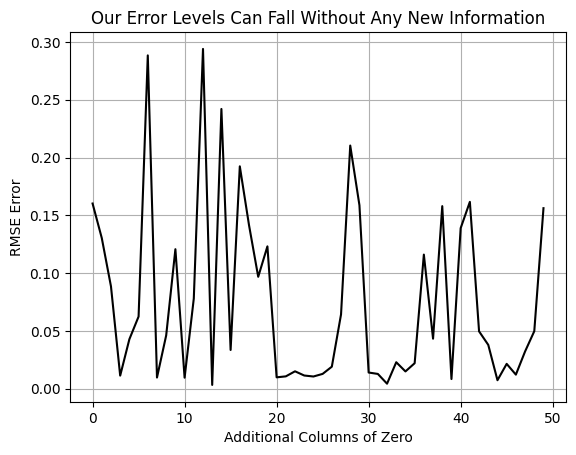

In [38]:
#Load our libraries
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import cross_val_score,TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5,gap=HORIZON)
EPOCHS = 50

#Observe what happens to our error levels as we increase the number of columns in the dataset
res = []

for i in np.arange(EPOCHS):
    #Fetch new data with addtional columns of zeros
    new_data = fill_zeros(X,(1+i))

    #Record the new error
    res.append(np.mean(np.abs(cross_val_score(MLPRegressor(hidden_layer_sizes=(new_data.iloc[:,1:-1].shape[1],2,50,100),random_state=0,shuffle=False),X.iloc[:,1:-1],X.iloc[:,-1],cv=tscv,n_jobs=-1))))

plt.plot(res,color='black')
plt.grid()
plt.ylabel('RMSE Error')
plt.xlabel('Additional Columns of Zero')
plt.title('Our Error Levels Can Fall Without Any New Information')

First I'd like to assess the value added by the columns I crafted by hand

In [43]:
data.iloc[:,1:-4].columns

Index(['True Open', 'True High', 'True Low', 'True Close', 'True MA C',
       'True MA O', 'True MA H', 'True MA L', 'Diff Open', 'Diff High',
       'Diff Low', 'Diff Close', 'Diff MA Close 2', 'Diff MA Open 2',
       'Diff MA High 2', 'Diff MA Low 2', 'O - C', 'Delta O - C', 'O - L',
       'Delta O - L', 'O - H', 'Delta O - H', 'H - L', 'Delta H - L', 'C - H',
       'Delta C - H', 'C - L', 'Delta C - L', 'MA O - C', 'MA Delta O - C',
       'MA O - L', 'MA Delta O - L', 'MA O - H', 'MA Delta O - H', 'MA H - L',
       'MA Delta H - L', 'MA C - H', 'MA Delta C - H', 'MA C - L',
       'MA Delta C - L'],
      dtype='object')

In [44]:
X = data.iloc[:,1:-4].columns

In [45]:
y = data['Target']
y2 = data['Target 2']
y3 = data['Target 3']

In [46]:
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import GradientBoostingClassifier,RandomForestClassifier

In [47]:
def get_model():
    return(RandomForestClassifier(random_state=0,n_estimators=500,max_depth=3,min_samples_leaf=20))

In [48]:
Z = pd.DataFrame(columns=['Z1','Z2'])

Z['Z1'] = data.loc[:,X].mean()
Z['Z2'] = data.loc[:,X].std()

Z['Z1'].values

array([ 1.23933432e+00,  1.24403263e+00,  1.23474846e+00,  1.23936216e+00,
        1.23935910e+00,  1.23933128e+00,  1.24402971e+00,  1.23474522e+00,
        3.83991053e-05,  3.60920275e-05,  3.66240614e-05,  3.55759706e-05,
        3.68749001e-05,  3.98194600e-05,  3.78958300e-05,  3.79070139e-05,
       -2.78415082e-05, -3.06646429e-05,  4.58586036e-03,  4.58408532e-03,
       -4.69831123e-03, -4.70061831e-03,  9.28417159e-03,  9.28470363e-03,
       -4.67046972e-03, -4.66995367e-03,  4.61370187e-03,  4.61474996e-03,
       -2.78151462e-05, -3.07597060e-05,  4.58606247e-03,  4.58415002e-03,
       -4.69842067e-03, -4.70034430e-03,  9.28448314e-03,  9.28449433e-03,
       -4.67060553e-03, -4.66958460e-03,  4.61387762e-03,  4.61490973e-03])

In [49]:
Z['Z2'].values

array([0.12576155, 0.12640182, 0.125071  , 0.12572605, 0.12568469,
       0.125719  , 0.12636385, 0.12503521, 0.0150256 , 0.01494947,
       0.01478075, 0.01493629, 0.0141562 , 0.01423137, 0.01419596,
       0.01404453, 0.00669432, 0.0066951 , 0.00482275, 0.004823  ,
       0.00493041, 0.00493002, 0.0063063 , 0.00630607, 0.0048614 ,
       0.0048616 , 0.00471017, 0.0047104 , 0.00471147, 0.00471252,
       0.00361188, 0.00361259, 0.00371563, 0.00371488, 0.00513505,
       0.00513498, 0.0037117 , 0.0037125 , 0.00353196, 0.00353191])

In [50]:
data.loc[:,X] = (data.loc[:,X] - data.loc[:,X].mean()) / data.loc[:,X].std()
data

C:\Users\Westwood\AppData\Local\Temp\ipykernel_13476\4104531654.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:,X] = (data.loc[:,X] - data.loc[:,X].mean()) / data.loc[:,X].std()


,Time,True Open,True High,True Low,True Close,True MA C,True MA O,True MA H,True MA L,Diff Open,...,MA H - L,MA Delta H - L,MA C - H,MA Delta C - H,MA C - L,MA Delta C - L,Target,Target 2,Target 3,Target 4
0,2003.01.01 00:00:00,-1.511864,-1.532673,-1.503534,-1.520466,-1.518157,-1.517124,-1.531528,-1.509137,1.108881,...,-0.941468,-0.698055,0.732981,1.136589,-0.598499,0.179815,1,1,1,0
1,2003.01.02 00:00:00,-1.519815,-1.535046,-1.609074,-1.607162,-1.564304,-1.516328,-1.534297,-1.556723,0.689597,...,0.149077,-0.328043,-0.735349,1.123121,-0.556030,0.703610,1,1,1,0
2,2003.01.03 00:00:00,-1.606487,-1.582514,-1.605076,-1.563416,-1.585787,-1.563656,-1.559225,-1.607509,-0.308700,...,0.772245,-0.737003,-0.614111,1.136589,0.477390,0.123188,1,1,1,0
3,2003.01.05 00:00:00,-1.569115,-1.592007,-1.544310,-1.565802,-1.565100,-1.588314,-1.587714,-1.575118,-0.069109,...,-0.717517,-0.707792,1.056283,0.974973,0.066853,-0.004221,1,1,1,0
4,2003.01.06 00:00:00,-1.565934,-1.537420,-1.539513,-1.553076,-1.559928,-1.568031,-1.565161,-1.542327,-0.375253,...,-0.960942,-0.425415,0.463563,0.799888,-0.909941,0.222285,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6254,2023.01.24 00:00:00,-1.210102,-1.220098,-1.208981,-1.195951,-1.203680,-1.213311,-1.211499,-1.204862,0.541849,...,-0.475065,0.299029,0.486463,-1.031762,-0.179469,-0.649764,0,0,0,0
6255,2023.01.25 00:00:00,-1.195392,-1.199766,-1.191391,-1.171453,-1.184067,-1.203130,-1.210273,-1.200504,0.610398,...,-0.551014,-0.066114,1.108820,-0.040516,0.364138,-0.138709,0,0,0,0
6256,2023.01.26 00:00:00,-1.170821,-1.195099,-1.196748,-1.193326,-1.182754,-1.183483,-1.197769,-1.194385,0.577787,...,-0.392301,-0.697081,0.727593,1.129855,0.194261,0.174152,0,0,0,0
6257,2023.01.27 00:00:00,-1.192688,-1.218199,-1.206982,-1.213688,-1.203878,-1.182131,-1.206988,-1.202183,0.184459,...,-0.429301,-1.175175,0.326159,1.141976,-0.281395,-0.508198,0,0,0,0


In [ ]:
import onnx
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(data.loc[:,X],data.loc[:,'Target 2'])

initial_types = [("FLOAT INPUT",FloatTensorType([1,len(X)]))]

model_proto = convert_sklearn(model,initial_types=initial_types,target_opset=12)

onnx.save(model_proto,"EURUSD LM MA D1.onnx")